# Cell Fate Dynamics: Exploring Pancreas Differentiation with scRNA-seq

A reproducible exploration of cell-state transitions, representation learning (PCA vs. scVI), and lineage dynamics (scVelo & CellRank).

### Objectives:
1. **Explore & preprocess** spliced/unspliced single-cell counts.
2. **Compare latent representations** (PCA linear baseline vs. scVI variational autoencoder).
3. **Infer transition trajectories** with scVelo RNA velocity.
4. **Predict terminal states & fate probabilities** using CellRank GPCCA.
5. **Quantify robustness & limitations** rather than relying solely on visual embeddings.

## 0. Setup and Reproducibility

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import scvelo as scv
import scvi
import cellrank as cr

scv.settings.verbosity = 1
sc.settings.verbosity = 1
RANDOM_SEED = 42
scvi.settings.seed = RANDOM_SEED
np.random.seed(RANDOM_SEED)

Seed set to 42


## 1. Data Exploration & Quality Control

We use the endocrine pancreas dataset (Bastidas-Ponce et al., 2019) containing developing islet cells.

Cells: 3696, Genes: 27998
Annotated cell types:
 clusters
Ductal           916
Ngn3 high EP     642
Pre-endocrine    592
Beta             591
Alpha            481
Ngn3 low EP      262
Epsilon          142
Delta             70
Name: count, dtype: int64


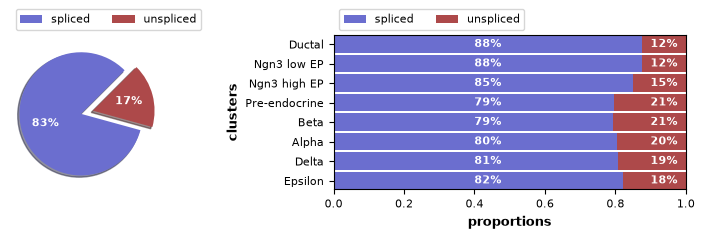

In [2]:
adata = scv.datasets.pancreas()
print(f'Cells: {adata.n_obs}, Genes: {adata.n_vars}')
print('Annotated cell types:\n', adata.obs['clusters'].value_counts())
scv.pl.proportions(adata)

## 2. Preprocessing & Quality Filtering

In [3]:
from cell_fate_dynamics.data import preprocess_data

# Store raw count layer for scVI
adata.layers['counts'] = adata.X.copy()
adata = preprocess_data(adata, min_shared_counts=20, n_top_genes=2000)
print('Filtered AnnData shape:', adata.shape)

Filtered AnnData shape: (3696, 2000)


## 3. Representation Learning: PCA baseline vs. scVI

We train an scVI variational autoencoder and compare its latent geometry against standard PCA.

Seed set to 42


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/home/arobin/Work/Repos/cell-fate-dynamics/.venv/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
/home/arobin/Work/Repos/cell-fate-dynamics/.venv/lib/python3.11/site-packages/lightning/pytorch/loops/fit_loop.py:321: The number of training batches (7) is smaller than the logging interval Trainer(log_every_n_steps=10). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.
/home/arobin/Work/Repos/cell-fate-dynamics/.venv/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Training:   0%|          | 0/45 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 8 records. Best score: 1450.829. Signaling Trainer to stop.


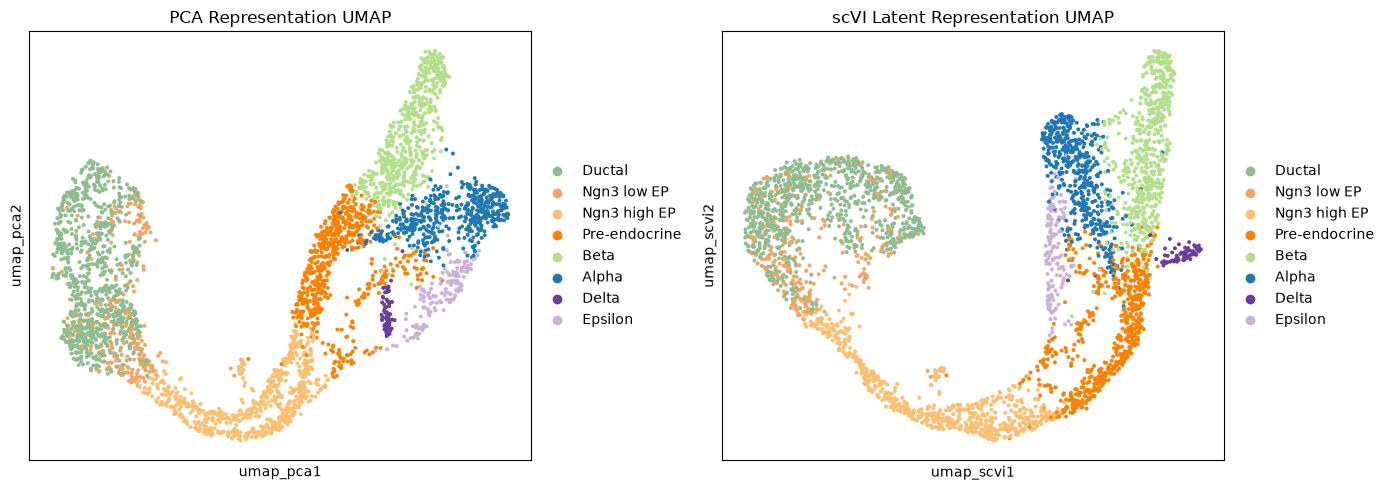

Silhouette score: PCA=0.1418, scVI=0.2322
k-NN Jaccard neighborhood overlap (k=15): 0.1392


In [4]:
from cell_fate_dynamics.models import train_scvi
from cell_fate_dynamics.evaluation import evaluate_representation_clustering, neighborhood_overlap

# Baseline PCA UMAP
sc.pp.neighbors(adata, n_pcs=30, n_neighbors=30, random_state=RANDOM_SEED, key_added='neighbors_pca')
sc.tl.umap(adata, neighbors_key='neighbors_pca', random_state=RANDOM_SEED)
adata.obsm['X_umap_pca'] = adata.obsm['X_umap'].copy()

# scVI model training on CPU
adata, vae = train_scvi(
    adata,
    layer='counts',
    n_latent=30,
    max_epochs=45,
    batch_size=512,
    seed=RANDOM_SEED,
    early_stopping=True,
    early_stopping_patience=8,
)

# scVI UMAP
sc.pp.neighbors(adata, use_rep='X_scVI', n_neighbors=30, random_state=RANDOM_SEED, key_added='neighbors_scvi')
sc.tl.umap(adata, neighbors_key='neighbors_scvi', random_state=RANDOM_SEED)
adata.obsm['X_umap_scvi'] = adata.obsm['X_umap'].copy()

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc.pl.embedding(adata, basis='umap_pca', color='clusters', ax=axes[0], show=False, title='PCA Representation UMAP')
sc.pl.embedding(adata, basis='umap_scvi', color='clusters', ax=axes[1], show=False, title='scVI Latent Representation UMAP')
plt.tight_layout()
plt.show()

# Quantitative metrics
sil = evaluate_representation_clustering(adata, cell_type_key='clusters', rep_keys=['X_pca', 'X_scVI'])
overlap = neighborhood_overlap(adata.obsm['X_pca'], adata.obsm['X_scVI'], n_neighbors=15)
print(f"Silhouette score: PCA={sil['X_pca']:.4f}, scVI={sil['X_scVI']:.4f}")
print(f"k-NN Jaccard neighborhood overlap (k=15): {overlap:.4f}")

## 4. RNA Velocity Dynamics (scVelo)

> **Methodological note**: The streamlines below project the *same* underlying RNA velocity model onto different 2D embeddings (PCA-derived vs. scVI-derived UMAP) to evaluate visual distortion and consistency across representations.

/home/arobin/Work/Repos/cell-fate-dynamics/.venv/lib/python3.11/site-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


  0%|          | 0/3696 [00:00<?, ?cells/s]

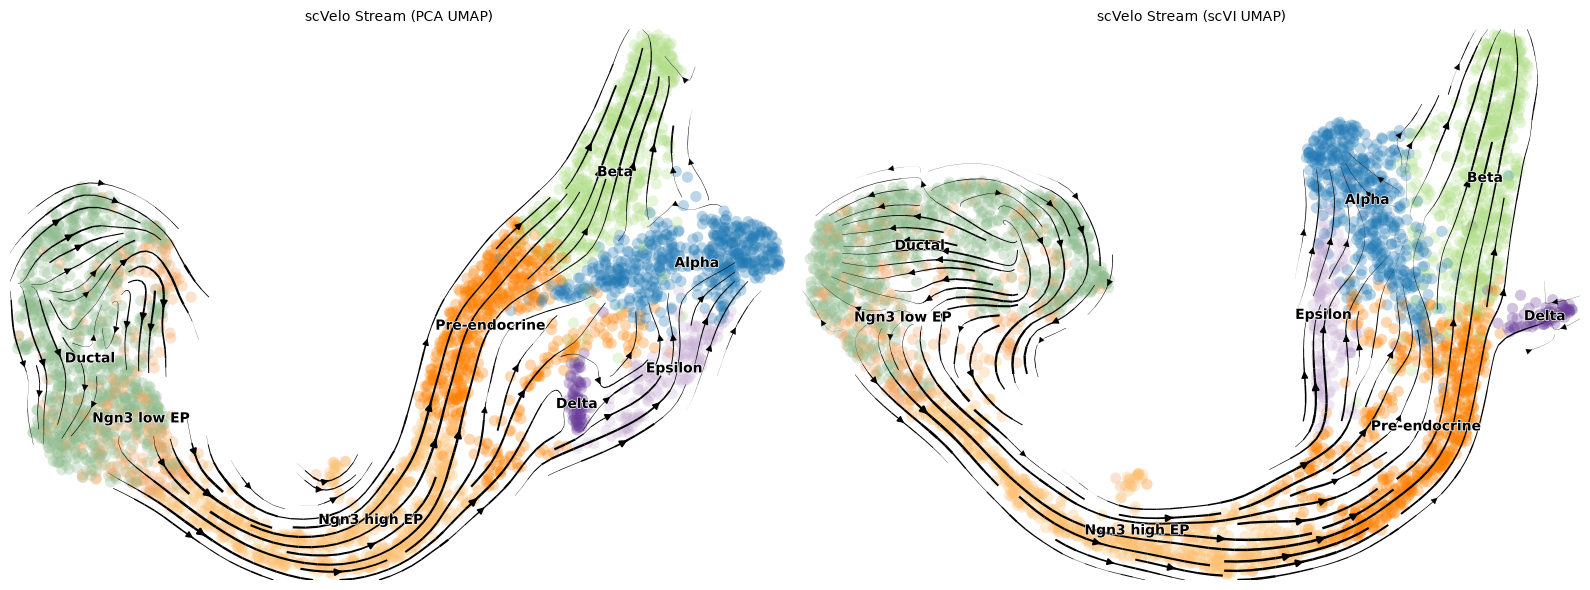

Mean velocity confidence: 0.7882210305808526


In [5]:
from cell_fate_dynamics.models import compute_velocity
from cell_fate_dynamics.evaluation import evaluate_velocity_confidence

adata = compute_velocity(adata, mode='stochastic', basis='umap_pca', n_jobs=-1)
scv.tl.velocity_embedding(adata, basis='umap_scvi')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
scv.pl.velocity_embedding_stream(adata, basis='umap_pca', color='clusters', ax=axes[0], show=False, title='scVelo Stream (PCA UMAP)')
scv.pl.velocity_embedding_stream(adata, basis='umap_scvi', color='clusters', ax=axes[1], show=False, title='scVelo Stream (scVI UMAP)')
plt.tight_layout()
plt.show()

conf = evaluate_velocity_confidence(adata)
print('Mean velocity confidence:', conf['mean_velocity_confidence'])

## 5. Terminal States & Lineage Drivers (CellRank GPCCA)

We use Generalized Perron Cluster Cluster Analysis (GPCCA) combining velocity and transcriptomic similarity to predict terminal states and fate probabilities.

  0%|          | 0/3696 [00:00<?, ?cell/s]

Predicted terminal states: ['Alpha', 'Ductal_2', 'Beta']


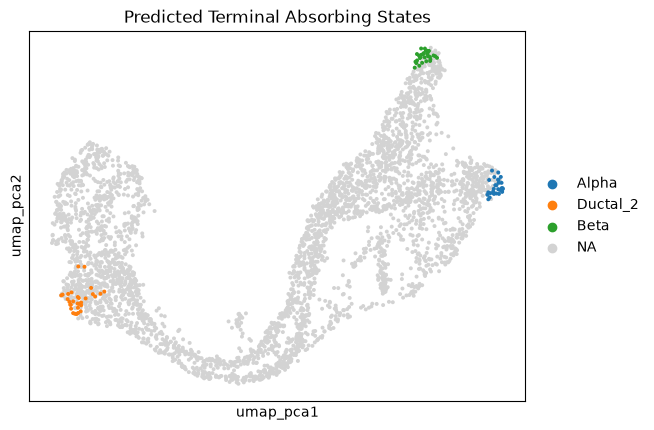

  0%|          | 0/3 [00:00<?, ?/s]

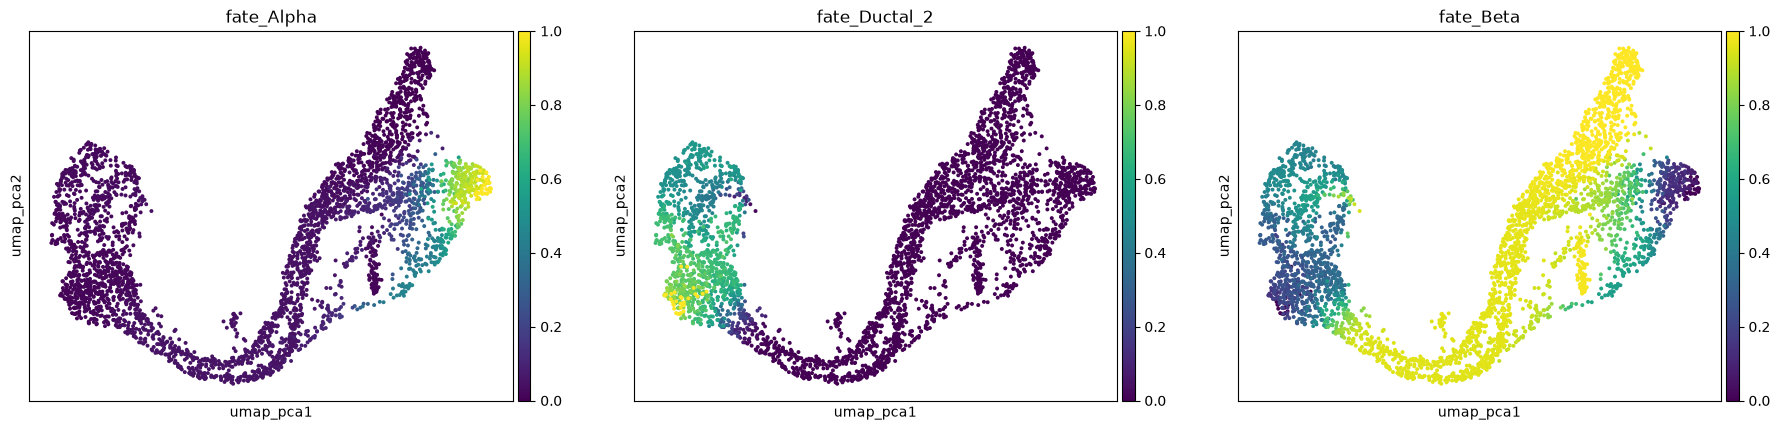


Top drivers for Alpha:
  Gcg: r = 0.889 (pval = 0.00e+00)
  Irx2: r = 0.691 (pval = 0.00e+00)
  Tmem27: r = 0.609 (pval = 0.00e+00)
  Peg10: r = 0.566 (pval = 0.00e+00)
  Tmsb15l: r = 0.549 (pval = 2.93e-307)

Top drivers for Ductal_2:
  Anxa2: r = 0.846 (pval = 0.00e+00)
  Spp1: r = 0.833 (pval = 0.00e+00)
  Bicc1: r = 0.813 (pval = 0.00e+00)
  1700011H14Rik: r = 0.808 (pval = 0.00e+00)
  Cyr61: r = 0.789 (pval = 0.00e+00)

Top drivers for Beta:
  Map1b: r = 0.553 (pval = 0.00e+00)
  Camk2n1: r = 0.551 (pval = 0.00e+00)
  Syt13: r = 0.547 (pval = 4.09e-304)
  Tubb3: r = 0.516 (pval = 5.70e-264)
  Aplp1: r = 0.463 (pval = 5.06e-204)


In [6]:
vk = cr.kernels.VelocityKernel(adata)
vk.compute_transition_matrix(n_jobs=-1, show_progress_bar=False)
ck = cr.kernels.ConnectivityKernel(adata)
ck.compute_transition_matrix()
combined_kernel = 0.8 * vk + 0.2 * ck

g = cr.estimators.GPCCA(combined_kernel)
g.compute_macrostates(n_states=5, cluster_key='clusters')

# Predict terminal states based on Markov chain stability
g.predict_terminal_states(method='stability')
adata.obs['terminal_states'] = g.terminal_states
terminals = list(g.terminal_states.cat.categories)
print('Predicted terminal states:', terminals)

sc.pl.embedding(adata, basis='umap_pca', color='terminal_states', title='Predicted Terminal Absorbing States')

# Fate probabilities
g.compute_fate_probabilities(solver='gmres', use_petsc=False)
for lineage in terminals:
    adata.obs[f'fate_{lineage}'] = np.array(g.fate_probabilities[:, lineage]).flatten()

sc.pl.embedding(adata, basis='umap_pca', color=[f'fate_{l}' for l in terminals], cmap='viridis')

# Lineage driver genes
df_drivers = g.compute_lineage_drivers(cluster_key='clusters')
for lineage in terminals:
    col = f'{lineage}_corr'
    top_genes = df_drivers.sort_values(by=col, ascending=False).head(5)
    print(f'\nTop drivers for {lineage}:')
    for gene, row in top_genes.iterrows():
        print(f'  {gene}: r = {row[col]:.3f} (pval = {row[f"{lineage}_pval"]:.2e})')

## 6. Robustness Evaluation & Limits of Inferences

We test how sensitive transition vectors are to gene subsampling (80% downsampling).

In [7]:
rng = np.random.default_rng(RANDOM_SEED)
sub_idx = rng.choice(adata.n_vars, size=int(adata.n_vars * 0.8), replace=False)
adata_sub = adata[:, sub_idx].copy()

scv.tl.velocity(adata_sub, mode='stochastic')
scv.tl.velocity_graph(adata_sub, n_jobs=-1)
scv.tl.velocity_confidence(adata_sub)

corr = float(np.corrcoef(adata.obs['velocity_confidence'].values, adata_sub.obs['velocity_confidence'].values)[0, 1])
print(f'Velocity confidence correlation (full vs. 80% gene subset): {corr:.4f}')

/home/arobin/Work/Repos/cell-fate-dynamics/.venv/lib/python3.11/site-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


  0%|          | 0/3696 [00:00<?, ?cells/s]

Velocity confidence correlation (full vs. 80% gene subset): 0.8214


## 7. Discussion & Scientific Conclusions

1. **Latent representations**: scVI achieves higher cell-type separation (silhouette score 0.232 vs. 0.142) by explicitly modeling library size and count overdispersion.
2. **Terminal state prediction**: GPCCA automatically identifies Alpha and Beta as stable terminal endpoints along with Ductal cells. Delta cells, being a minor subpopulation (~70 cells), require careful interpretation as their stability index is lower.
3. **Inference boundaries**: High velocity confidence does not guarantee true biological differentiation time; directional coherence can be sensitive to gene selection when falling below 80% of top variable genes.